1.introdution

Customer segmentation is the process of dividing
customers into groups based on similarities in
their characteristics and purchasing behaviour.

This project applies Unsupervised Learning using
the K-Means clustering algorithm to identify
meaningful customer segments.

In [2]:
# import Libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [5]:
df = pd.read_csv('./datasets/Mall_Customers.csv')
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [6]:
print("Dataset Shape",df.shape)
print("rows",df.shape[0])
print("Column",df.shape[1])

Dataset Shape (200, 5)
rows 200
Column 5


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
df.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [11]:
print(df['Gender'].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64


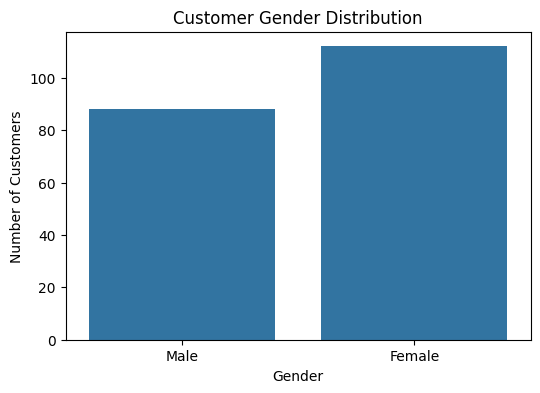

In [12]:
plt.figure(figsize = (6,4))
sns.countplot(data = df,x='Gender')
plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()


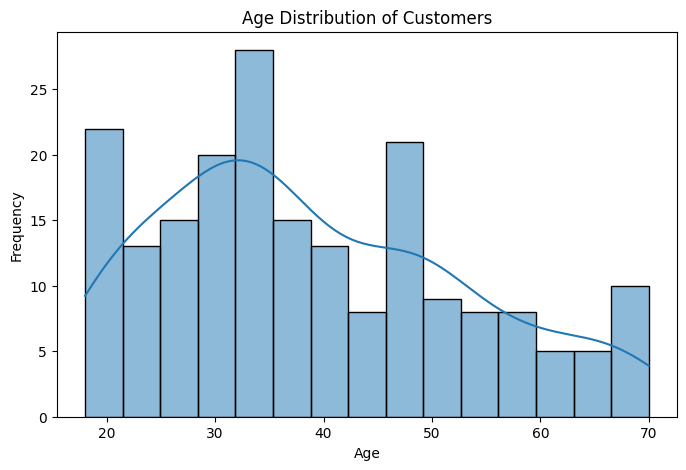

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

In [14]:
df['Age'].skew()

np.float64(0.48556885096681657)

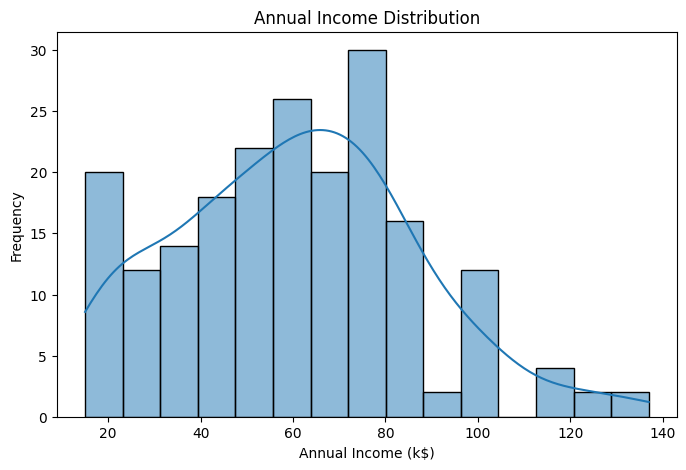

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Annual Income (k$)',
    bins=15,
    kde=True
)

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Frequency')

plt.show()

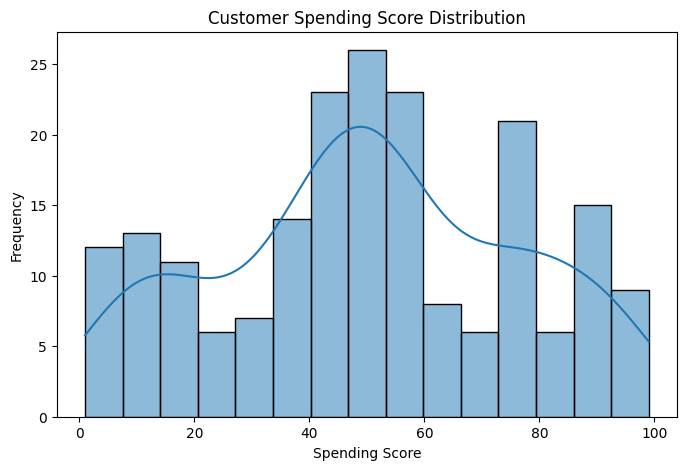

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Spending Score (1-100)',
    bins=15,
    kde=True
)

plt.title('Customer Spending Score Distribution')
plt.xlabel('Spending Score')
plt.ylabel('Frequency')

plt.show()

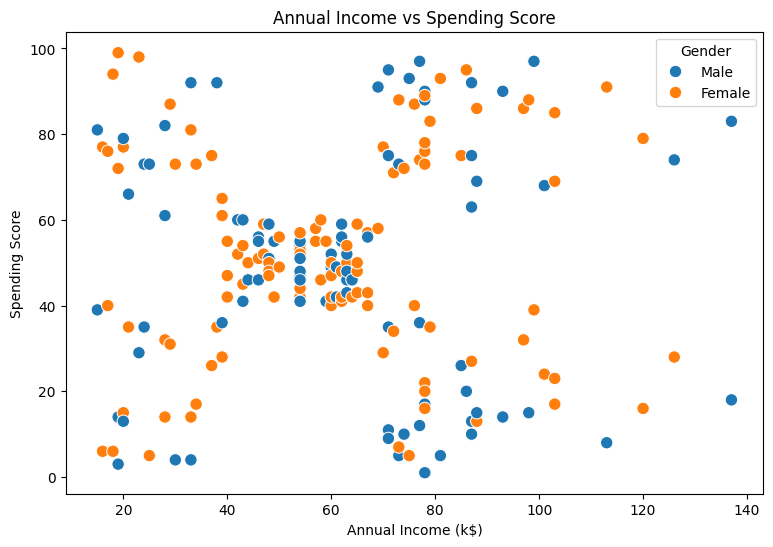

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=80
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')

plt.legend(title='Gender')
plt.show()

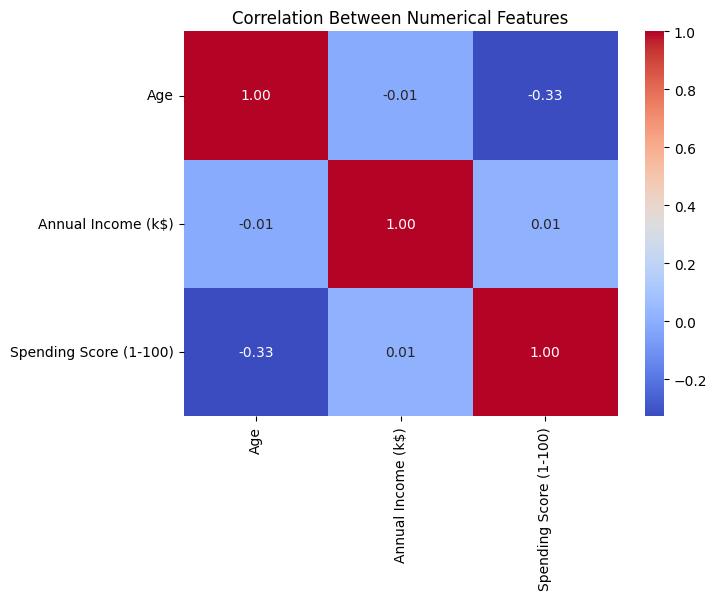

In [20]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[['Age', 'Annual Income (k$)',
        'Spending Score (1-100)']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Features')

plt.show()

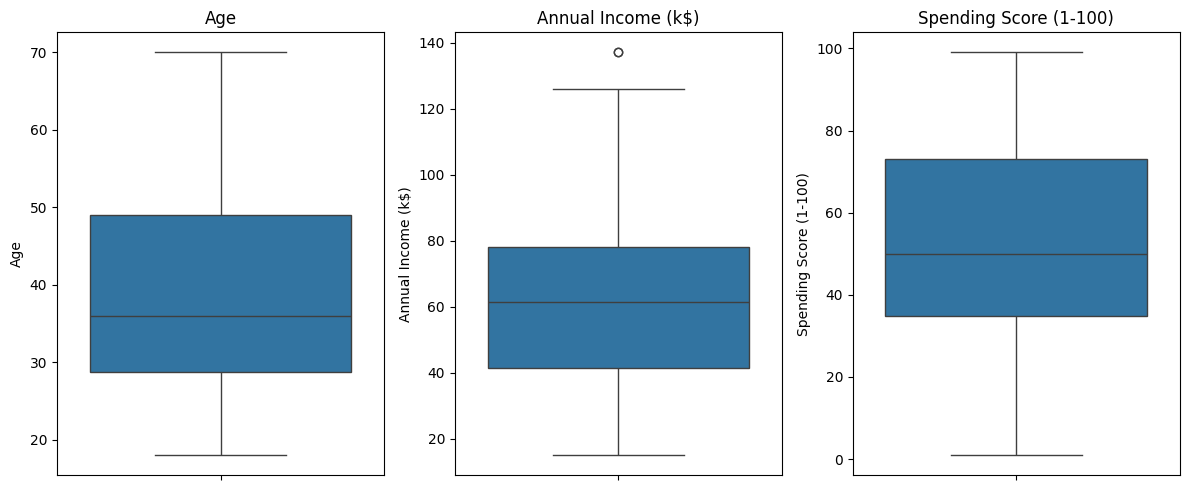

In [21]:
numerical_cols = [
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

plt.figure(figsize=(12, 5))

for i, col in enumerate(numerical_cols, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

In [23]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [24]:
print("Feature Dataset Shape:", X.shape)

Feature Dataset Shape: (200, 2)


In [25]:
Q1 = X['Annual Income (k$)'].quantile(0.25)

Q3 = X['Annual Income (k$)'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = X[
    (X['Annual Income (k$)'] < lower_bound) |
    (X['Annual Income (k$)'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Number of Outliers:", len(outliers))

outliers

Q1: 41.5
Q3: 78.0
IQR: 36.5
Lower Bound: -13.25
Upper Bound: 132.75
Number of Outliers: 2


,Annual Income (k$),Spending Score (1-100)
198,137,18
199,137,83


In [28]:
df.loc[outliers.index]

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [26]:


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [27]:
print("Mean of Scaled Features:")
print(X_scaled.mean())

print("\nStandard Deviation:")
print(X_scaled.std())

Mean of Scaled Features:
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation:
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


In [29]:
from sklearn.cluster import KMeans

wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print(wcss)

[269.691012192764, 157.7040081503594, 108.92131661364358, 65.56840815571681, 55.057348270386015, 44.86475569922557, 37.228187677585886, 32.39226763033117, 29.981897788243703]


The Elbow Method was applied to determine the
optimal number of clusters.

The WCSS decreases significantly as the number
of clusters increases from 2 to 5.

After K = 5, the rate of reduction becomes
comparatively smaller.

**Inference:**

The elbow point appears around K = 5,
making five clusters a potential choice for
customer segmentation.

The result will be further validated using
the Silhouette Score.

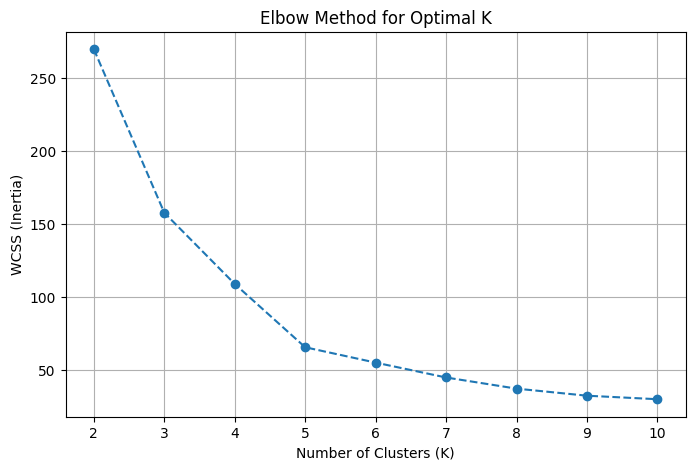

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    wcss,
    marker='o',
    linestyle='--'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()



In [32]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


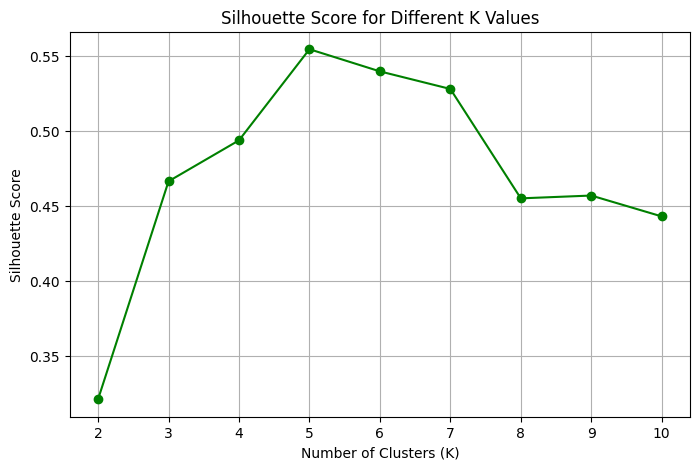

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o',
    color='green'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

The Silhouette Score was calculated for cluster
numbers ranging from 2 to 10.

- K = 2 produced a score of approximately 0.321.
- The score improved as K increased.
- K = 5 achieved the highest score of approximately 0.555.
- Beyond K = 5, the Silhouette Score generally decreased.

**Inference:**

K = 5 provides the highest Silhouette Score
among the tested configurations, indicating
relatively better-defined and separated clusters.

Training the k-means model

In [36]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [37]:
cluster_counts = df['Cluster'].value_counts().sort_index()

print(cluster_counts)

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


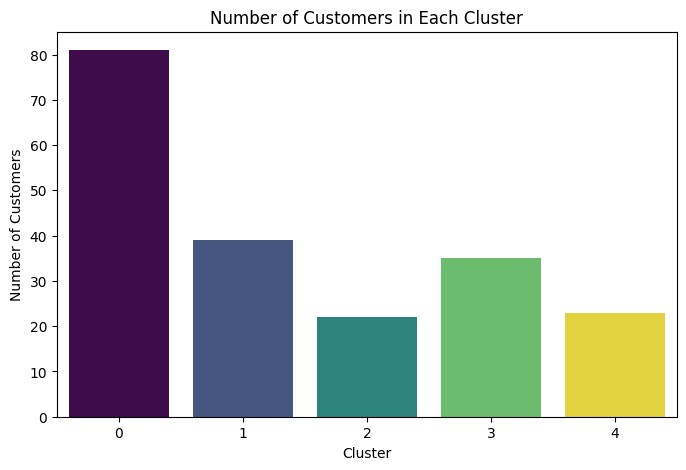

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.show()

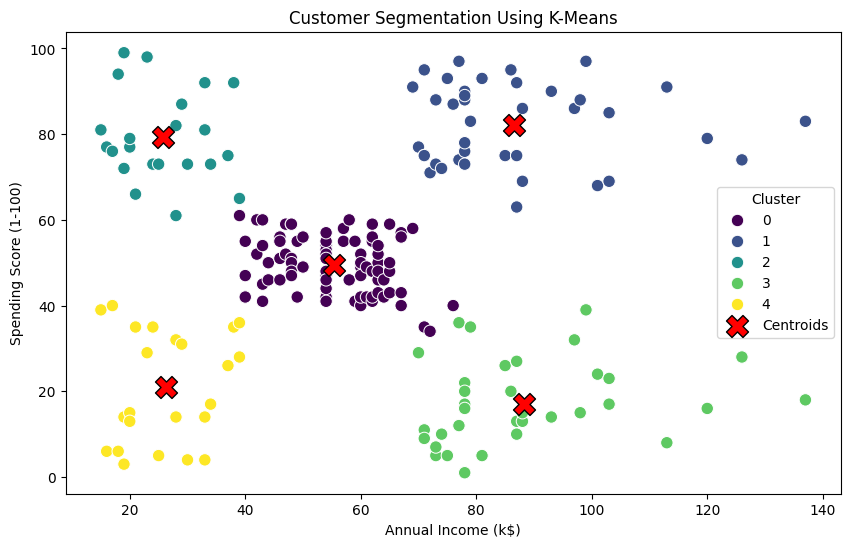

In [39]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    color='red',
    edgecolor='black',
    label='Centroids'
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')

plt.show()

In [40]:
cluster_analysis = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

cluster_analysis

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


- Female customers represent the majority in four clusters.
- Cluster 3 has a slightly higher proportion of male customers.
- Both genders are represented across all five clusters.

In [41]:
pd.crosstab(
    df['Cluster'],
    df['Gender'],
    normalize='index'
).mul(100).round(2)

Gender,Female,Male
Cluster,,
0,59.26,40.74
1,53.85,46.15
2,59.09,40.91
3,45.71,54.29
4,60.87,39.13


In [42]:
final_score = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("Final Silhouette Score:", round(final_score, 4))

Final Silhouette Score: 0.5547


In [43]:
cluster_names = {
    0: 'Average Customers',
    1: 'Premium Customers',
    2: 'Enthusiastic Spenders',
    3: 'High Income Low Spending',
    4: 'Budget Conscious Customers'
}

df['Segment'] = df['Cluster'].map(cluster_names)

df[['CustomerID', 'Cluster', 'Segment']].head(10)

,CustomerID,Cluster,Segment
0,1,4,Budget Conscious Customers
1,2,2,Enthusiastic Spenders
2,3,4,Budget Conscious Customers
3,4,2,Enthusiastic Spenders
4,5,4,Budget Conscious Customers
5,6,2,Enthusiastic Spenders
6,7,4,Budget Conscious Customers
7,8,2,Enthusiastic Spenders
8,9,4,Budget Conscious Customers
9,10,2,Enthusiastic Spenders


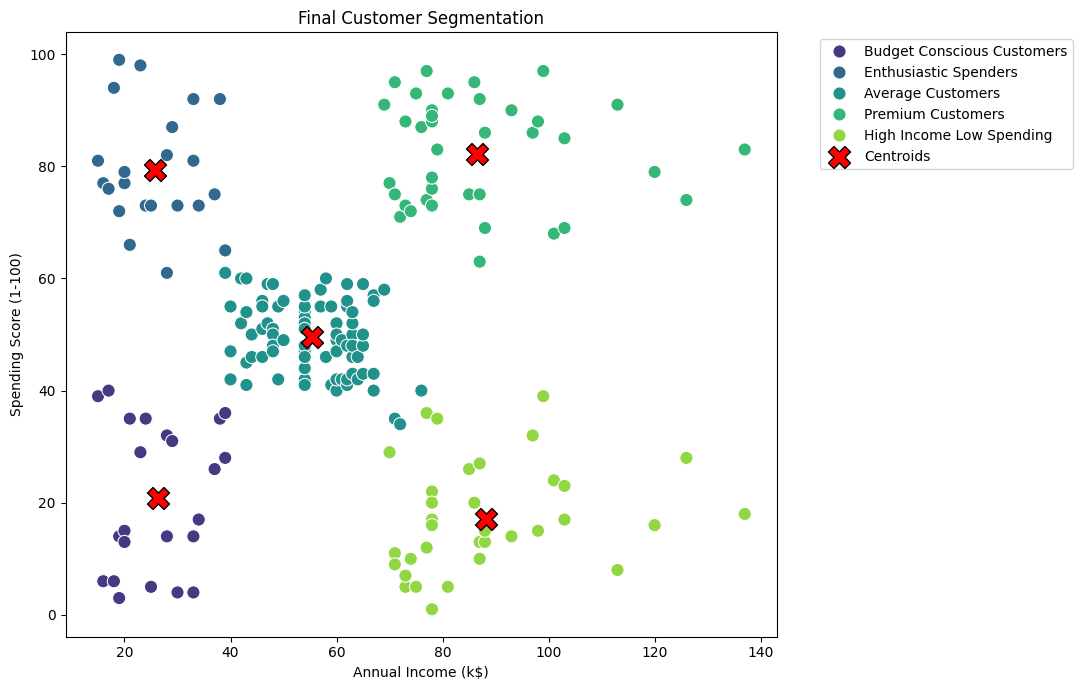

In [44]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Segment',
    palette='viridis',
    s=90
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    color='red',
    edgecolor='black',
    label='Centroids'
)

plt.title('Final Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()